# CMPT 459 Project: EDA Notebook
**Predicting High-Impact Traffic Accidents (US Accidents 2016-2023)**

Team: *(add names here)*

**How to use this notebook**
- Every section below has an **Owner** line. Put your name there once the team agrees on the split.
- Code cells are a working starter. Extend or replace them in your own section.
- Each section ends with a **Notes** cell. Write these in your own words after you look at your actual plots (the guidelines don't allow LLM-written prose).
- Do not clear outputs before committing. The notebook must run top-to-bottom with *Restart & Run All* and no edits.

---
## 0. Setup and configuration
**Owner:** _TBD_  |  **Tasks:** shared imports, config, and data loading. Everyone depends on this, so change it only through a PR.

In [31]:
import os, sys, glob, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

SAMPLE_FILE = "US_Accidents_March23_sampled_500k.csv"
KAGGLE_SLUG = "sobhanmoosavi/us-accidents"

In [32]:
def _find_csvs(folder):
    return sorted(glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True))

def find_or_download_csv():
    """Return (path, is_sample). Tries: local/Kaggle input -> kagglehub single file ->
    forced fresh download -> whole dataset folder (sample by name, else the full CSV)."""
    # 1) already on disk (Kaggle notebook input, local data/ folder, current folder)
    local = [f"/kaggle/input/us-accidents/{SAMPLE_FILE}", os.path.join("data", SAMPLE_FILE), SAMPLE_FILE]
    for p in local:
        if os.path.exists(p):
            return p, True
    hits = glob.glob(f"/kaggle/input/**/*sampled*500k*.csv", recursive=True)
    if hits:
        return hits[0], True

    try:
        import kagglehub
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub

    # 2) download just the sample file (retry once with a forced refresh: Colab's cache can be stale)
    for force in (False, True):
        try:
            return kagglehub.dataset_download(KAGGLE_SLUG, path=SAMPLE_FILE, force_download=force), True
        except Exception as e:
            print(f"[single-file download failed (force_download={force})]: {type(e).__name__}: {e}")

    # 3) download the whole dataset folder and look at what is really in it
    folder = kagglehub.dataset_download(KAGGLE_SLUG, force_download=True)
    csvs = _find_csvs(folder)
    print("CSV files found in dataset folder:", [os.path.basename(c) for c in csvs])
    sampled = [c for c in csvs if "sampled" in os.path.basename(c).lower() or "500k" in os.path.basename(c).lower()]
    if sampled:
        return sampled[0], True
    if csvs:                                   # fall back to the full file; we sample it below
        return max(csvs, key=os.path.getsize), False
    raise FileNotFoundError("No CSV found in the Kaggle dataset download.")

def load_data(path, is_sample, n_target=500_000, full_rows=7_728_394):
    """Load the 500k sample. If we only have the full file, draw a reproducible ~500k random sample from it in chunks."""
    if is_sample:
        return pd.read_csv(path)
    print("Full file found instead of the sample: drawing a reproducible ~500k random sample (takes a few minutes)...")
    frac = n_target / full_rows
    parts = [c.sample(frac=frac, random_state=RANDOM_SEED)
             for c in pd.read_csv(path, chunksize=500_000)]
    return pd.concat(parts, ignore_index=True)

DATA_PATH, IS_SAMPLE = find_or_download_csv()
print("Loading:", DATA_PATH)
df_raw = load_data(DATA_PATH, IS_SAMPLE)
print("Loaded shape:", df_raw.shape)


[single-file download failed (force_download=False)]: KaggleApiHTTPError: 404 Client Error.

Resource not found at URL: https://kaggle.com/datasets/sobhanmoosavi/us-accidents/versions/13
Please make sure you specified the correct resource identifiers.
[single-file download failed (force_download=True)]: KaggleApiHTTPError: 404 Client Error.

Resource not found at URL: https://kaggle.com/datasets/sobhanmoosavi/us-accidents/versions/13
Please make sure you specified the correct resource identifiers.


100%|██████████| 653M/653M [00:23<00:00, 29.0MB/s] 

Extracting files...


CSV files found in dataset folder: ['US_Accidents_March23.csv']
Loading: C:\Users\RiyaM\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv
Full file found instead of the sample: drawing a reproducible ~500k random sample (takes a few minutes)...
Loaded shape: (499996, 46)


In [33]:
# ---- Shared feature configuration (final feature list) ----
TARGET_COL = "Severity"

NUMERIC_FEATURES     = ["Start_Lat", "Start_Lng", "Temperature(F)", "Humidity(%)", "Pressure(in)",
                        "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
CATEGORICAL_FEATURES = ["Weather_Condition", "Sunrise_Sunset"]
BOOLEAN_FEATURES     = ["Amenity", "Crossing", "Junction", "Railway", "Station", "Stop", "Traffic_Signal"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BOOLEAN_FEATURES      # 17 raw model features

# Start_Time is not used raw; it is transformed into these model features (year is deliberately NOT one of them)
DERIVED_TIME_FEATURES = ["hour", "dayofweek", "month", "is_weekend", "rush_hour"]
MODEL_FEATURES = FEATURES + DERIVED_TIME_FEATURES

# Looked at in EDA only, NOT used for modelling:
LEAKAGE_FEATURES = ["End_Time"]           # only known after the accident clears (target is delay)
LOW_VARIANCE_FEATURES = ["Roundabout", "Turning_Loop", "Bump", "Traffic_Calming", "No_Exit", "Give_Way"]  # ~constant
RAW_SELECTED = FEATURES + ["Start_Time"] + LEAKAGE_FEATURES + LOW_VARIANCE_FEATURES

# Other columns excluded from modelling: post-accident info (End_Lat/Lng, Distance, Description),
# heavy missingness (Wind_Chill), or not useful (Weather_Timestamp). Source is for diagnostics only.
OTHER_EXCLUDED_COLS = ["End_Lat", "End_Lng", "Distance(mi)", "Description", "Wind_Chill(F)", "Weather_Timestamp", "Source"]

print(f"{len(FEATURES)} raw model features + Start_Time -> {len(MODEL_FEATURES)} model features after time transformation")
print(f"{len(RAW_SELECTED)} raw columns examined in this notebook (incl. EDA-only ones)")
missing_cols = [c for c in RAW_SELECTED + [TARGET_COL] if c not in df_raw.columns]
assert not missing_cols, f"Columns not found in data: {missing_cols}"

17 raw model features + Start_Time -> 22 model features after time transformation
25 raw columns examined in this notebook (incl. EDA-only ones)


---
## 1. Data loading and overview
**Owner:** _TBD_

**Tasks**
- Shape, dtypes, memory usage, `head()`, summary statistics.
- Time span of the data (min/max `Start_Time`).
- Table of the selected features and the role of each (model feature, transformed, EDA only).

In [34]:
df = df_raw.copy()
for c in ["Start_Time", "End_Time"]:
    df[c] = pd.to_datetime(df[c], errors="coerce", format="mixed")

print("Rows, columns:", df.shape)
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print("Time span:", df["Start_Time"].min(), "->", df["Start_Time"].max())
df.head()

Rows, columns: (499996, 46)
Memory: 596.8 MB
Time span: 2016-02-08 07:59:35 -> 2023-03-31 22:59:30


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-104248,Source2,2,2016-04-25 17:18:11,2016-04-25 18:18:11,33.939304,-117.218231,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,CA-60 W,Moreno Valley,Riverside,CA,92553,US,US/Pacific,KRIV,2016-04-25 16:58:00,63.9,NaN,29.0,29.80,10.0,West,11.5,NaN,Clear,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
1,A-199683,Source2,2,2017-01-10 09:40:16,2017-01-10 10:10:02,42.549671,-71.847313,NaN,NaN,0.01,Accident on MA-2 Eastbound before MA-31 Prince...,MA-2 E,Fitchburg,Worcester,MA,01420,US,US/Eastern,KFIT,2017-01-10 09:52:00,19.0,13.9,71.0,30.66,10.0,SSW,3.5,NaN,Clear,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
2,A-140206,Source2,3,2016-09-02 17:27:56,2016-09-02 18:27:56,26.203491,-80.143852,NaN,NaN,0.00,Center lane blocked due to accident on I-95 No...,NE 62nd St,Fort Lauderdale,Broward,FL,33334,US,US/Eastern,KFXE,2016-09-02 17:53:00,91.0,NaN,48.0,29.99,10.0,SW,12.7,NaN,Clear,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
3,A-132821,Source2,2,2016-09-29 18:07:37,2016-09-29 18:51:28,27.440348,-82.575432,NaN,NaN,0.00,Left lane blocked due to accident on US-41 14t...,14th St W,Bradenton,Manatee,FL,34207-3610,US,US/Eastern,KSRQ,2016-09-29 18:05:00,77.0,NaN,88.0,30.02,1.5,Variable,3.5,0.08,Heavy Thunderstorms and Rain,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day
4,A-408710,Source2,3,2017-05-03 12:12:18,2017-05-03 12:44:00,33.901752,-118.370316,NaN,NaN,0.01,Multi-vehicle accident on I-405 Northbound at ...,W Rosecrans Ave,Hawthorne,Los Angeles,CA,90250,US,US/Pacific,KHHR,2017-05-03 11:53:00,72.0,NaN,61.0,29.96,10.0,WSW,8.1,NaN,Clear,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day


In [35]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "example": df.iloc[0],
})
overview

,dtype,n_unique,example
ID,str,499996,A-104248
Source,str,3,Source2
Severity,int64,4,2
Start_Time,datetime64[ns],482175,2016-04-25 17:18:11
End_Time,datetime64[ns],491639,2016-04-25 18:18:11
Start_Lat,float64,369757,33.939304
Start_Lng,float64,370950,-117.218231
End_Lat,float64,220490,NaN
End_Lng,float64,221593,NaN
Distance(mi),float64,10691,0.01


In [36]:
df[NUMERIC_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
Start_Lat,499996.0,36.212602,5.071976,24.555269,33.411053,35.835129,40.088727,49.000560
Start_Lng,499996.0,-94.707786,17.391256,-124.548074,-117.221464,-87.768452,-80.357706,-67.553307
Temperature(F),489386.0,61.652195,19.016246,-89.000000,49.000000,64.000000,76.000000,172.000000
Humidity(%),488718.0,64.863259,22.808652,1.000000,48.000000,67.000000,84.000000,100.000000
Pressure(in),490944.0,29.538732,1.002753,0.300000,29.370000,29.860000,30.030000,39.450000
Visibility(mi),488515.0,9.091196,2.703783,0.000000,10.000000,10.000000,10.000000,100.000000
Wind_Speed(mph),463042.0,7.680385,5.295212,0.000000,4.600000,7.000000,10.400000,243.000000
Precipitation(in),357162.0,0.008062,0.088623,0.000000,0.000000,0.000000,0.000000,10.160000


In [37]:
roles = (
    [(c, "numeric", "model feature") for c in NUMERIC_FEATURES]
    + [(c, "categorical", "model feature") for c in CATEGORICAL_FEATURES]
    + [(c, "boolean", "model feature") for c in BOOLEAN_FEATURES]
    + [("Start_Time", "datetime", "transformed into hour/day/month/weekend/rush-hour")]
    + [(c, "datetime", "EDA only (leakage: known after the accident)") for c in LEAKAGE_FEATURES]
    + [(c, "boolean", "EDA only (near-constant)") for c in LOW_VARIANCE_FEATURES]
)
feature_table = pd.DataFrame(roles, columns=["feature", "type", "role"])
print("Other columns excluded from modelling:", OTHER_EXCLUDED_COLS)
feature_table

Other columns excluded from modelling: ['End_Lat', 'End_Lng', 'Distance(mi)', 'Description', 'Wind_Chill(F)', 'Weather_Timestamp', 'Source']


,feature,type,role
0,Start_Lat,numeric,model feature
1,Start_Lng,numeric,model feature
2,Temperature(F),numeric,model feature
3,Humidity(%),numeric,model feature
4,Pressure(in),numeric,model feature
5,Visibility(mi),numeric,model feature
6,Wind_Speed(mph),numeric,model feature
7,Precipitation(in),numeric,model feature
8,Weather_Condition,categorical,model feature
9,Sunrise_Sunset,categorical,model feature


In [47]:
print(df["Wind_Direction"].value_counts(dropna=False).to_string())

Wind_Direction
CALM        62513
S           27306
W           24898
SSW         24884
WNW         24561
NW          23790
Calm        23751
SW          23530
WSW         22907
SSE         22401
NNW         21605
N           19886
SE          19137
E           17831
ESE         17277
NE          16738
NNE         16651
ENE         16566
VAR         16069
South       11596
NaN         11443
West        10623
North        9967
Variable     7374
East         6692


In [48]:
wd = df.groupby("Wind_Direction")["target"].agg(["mean", "count"])
wd["sev4_rate_%"] = (wd["mean"] * 100).round(2)
display(wd[["sev4_rate_%", "count"]].sort_values("sev4_rate_%"))

,sev4_rate_%,count
Wind_Direction,,
VAR,1.74,16069
SE,2.15,19137
E,2.19,17831
Variable,2.26,7374
ESE,2.27,17277
ENE,2.31,16566
SSE,2.38,22401
NE,2.41,16738
N,2.45,19886


In [49]:
df.groupby("Timezone")["Start_Lng"].agg(["min", "median", "max", "count"]).round(1)

,min,median,max,count
Timezone,,,,
US/Central,-104.6,-93.5,-83.5,106523
US/Eastern,-87.7,-80.2,-67.6,231577
US/Mountain,-118.1,-111.8,-98.0,27969
US/Pacific,-124.5,-119.1,-90.0,133430


In [53]:
pd.crosstab(df["Sunrise_Sunset"], df["Civil_Twilight"])

Civil_Twilight,Day,Night
Sunrise_Sunset,,
Day,345493,5
Night,23328,129630


In [54]:
pd.crosstab(df["Sunrise_Sunset"], df["Nautical_Twilight"])

Nautical_Twilight,Day,Night
Sunrise_Sunset,,
Day,345498,0
Night,47880,105078


In [55]:
pd.crosstab(df["Sunrise_Sunset"], df["Astronomical_Twilight"])

Astronomical_Twilight,Day,Night
Sunrise_Sunset,,
Day,345140,358
Night,67686,85272


In [51]:
print(df[["Wind_Chill(F)", "Temperature(F)", "Wind_Speed(mph)"]].corr().round(2))

                 Wind_Chill(F)  Temperature(F)  Wind_Speed(mph)
Wind_Chill(F)             1.00            0.99            -0.05
Temperature(F)            0.99            1.00             0.03
Wind_Speed(mph)          -0.05            0.03             1.00



**Notes (write in your own words):**

1) Sample size and period it covers =
    rows (records) are 499996 ~ sample size. 
   It covers for about 2016-02-08  -> 2023-03-31 (more than 7 years)

2) types of columns = 
    boolean(eg, crossing), numerical(eg, humidity), datetime (start_time), ordinal(severity), string(eg, description), nominal (wind direction)

3) Stood out?
    Impossible values= 
    Temperature = min: -89 , max: 172   
    pressure = min: 0.3
    wind speed = max: 243
    Suspicious values = 
    visibility = max: 100
    precipitation = max: 10.16

4) Columns excluded?
    Known after accidents(leakage) = End_Lat, End_Lng, Distance, Description. End_Time.
    IF we include this, the information will not be complete at the time of initial report, which will cause the test result to be unrealistically high. 
    Source is for diagnostics only. 
    Wind_Direction: Dropped. There are spelling inconsistencies, and all of them have different rates (eg, CALM, Calm, both have different rates), this fails to collect the actual wind pattern. Additionally, There are about 16 separate categories for it, encoding it all is not useful/justifieable.
    ID = identifier, no meaning/use to the data/target.
    Near constant/constant = Roundabout, Turning_Loop, Bump, Traffic_Calming, No_Exit, Give_Way, Country
    Location columns that lat and long alreaady carry = Street, City, County, Zipcode, Airport_Code, State
    Redundant with kept columns =  
    Timezone: largely redundant with longitude. 
    Wind_Chill has 99% correlation with temperature.
    Weather_Timestamp: redundant with Start_Time. 
    LArgely overlap with Sunrise_Sunset =
    Civil_Twilight: 95.3% agreement with sunrise_sunset
    Nautical_Twilight: 90.4% Astronomical_Twilight: 86.3%

5) Columns kept?
    Start_Time (transformed into hour/day/month/weekend/rush-hour), 
    Start_Lat, Start_Lng, Temperature(F), Humidity(%), Pressure(in), Visibility(mi), Wind_Speed(mph), Precipitation(in), Weather_Condition (grouped), Sunrise_Sunset, Amenity, Crossing, Junction, Railway, Station, Stop, Traffic_Signal

6) Target = severity --> binary (0 = 1-3, 1 = 4)






---
## 2. Target definition and class balance
**Owner:** _TBD_

**Tasks**
- Convert `Severity` to binary: **1 = severity 4 (high impact)**, 0 = severity 1-3.
- Class counts and percentages, original 4-level distribution plus the binary one.
- How the positive-class rate changes by year (the proposal flags this as a challenge).
- Derive time features from `Start_Time` (hour, day of week, month, weekend flag, rush-hour flag; year is for EDA only).
- Accident duration (`End_Time` - `Start_Time`) by severity, as evidence for why severity 4 = long delay. EDA only.

Original severity counts:
 Severity
1      4387
2    398309
3     84028
4     13272
Name: count, dtype: int64 

Binary target counts:
 target
0    486724
1     13272
Name: count, dtype: int64

Positive class (severity 4): 2.65%


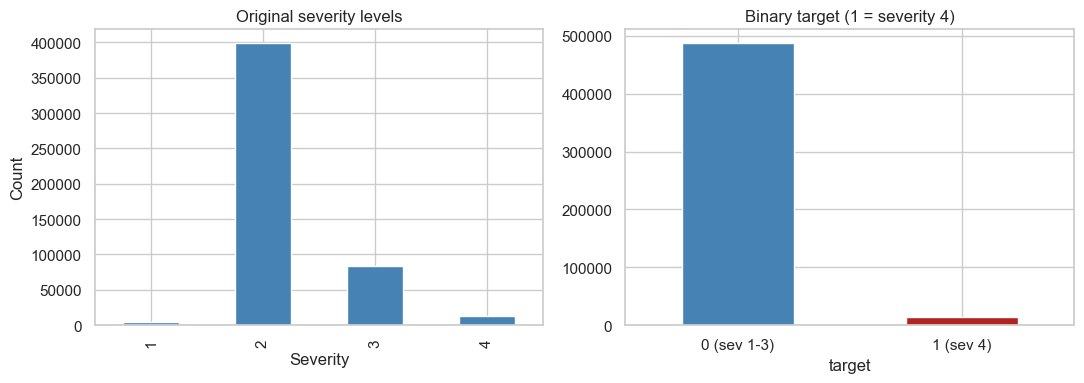

In [38]:
df["target"] = (df[TARGET_COL] == 4).astype(int)

df["hour"] = df["Start_Time"].dt.hour
df["dayofweek"] = df["Start_Time"].dt.dayofweek      # 0 = Monday
df["month"] = df["Start_Time"].dt.month
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
df["rush_hour"] = ((df["dayofweek"] < 5) & (df["hour"].between(7, 9) | df["hour"].between(16, 18))).astype(int)
df["year"] = df["Start_Time"].dt.year                # EDA only, not a model feature

orig = df[TARGET_COL].value_counts().sort_index()
binary = df["target"].value_counts().sort_index()
print("Original severity counts:\n", orig, "\n")
print("Binary target counts:\n", binary)
print(f"\nPositive class (severity 4): {df['target'].mean() * 100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
orig.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Original severity levels"); axes[0].set_xlabel("Severity"); axes[0].set_ylabel("Count")
binary.plot(kind="bar", ax=axes[1], color=["steelblue", "firebrick"])
axes[1].set_title("Binary target (1 = severity 4)"); axes[1].set_xticklabels(["0 (sev 1-3)", "1 (sev 4)"], rotation=0)
plt.tight_layout(); plt.show()

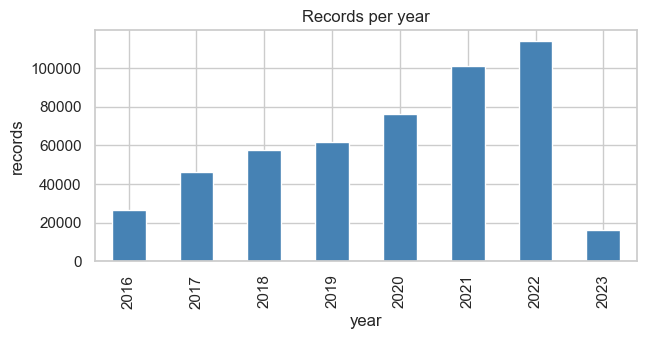

In [ ]:
# Records per year (2016 and 2023 are partial years)
by_year["n_total"].plot(kind="bar", figsize=(7, 3), color="steelblue", title="Records per year")
plt.ylabel("records"); plt.show()

,positive_rate,n_positive,n_total
year,,,
2016,0.036184,963,26614
2017,0.034708,1613,46474
2018,0.028579,1653,57840
2019,0.029638,1827,61643
2020,0.026328,2007,76232
2021,0.019912,2015,101196
2022,0.023974,2733,113997
2023,0.028813,461,16000


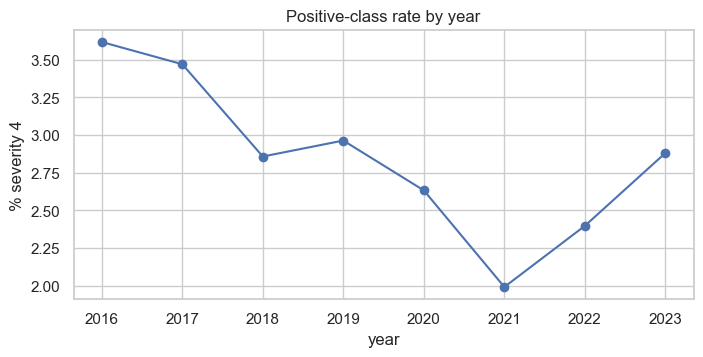

In [40]:
by_year = df.groupby("year")["target"].agg(["mean", "sum", "count"])
by_year.columns = ["positive_rate", "n_positive", "n_total"]
display(by_year)

ax = (by_year["positive_rate"] * 100).plot(marker="o", figsize=(8, 3.5))
ax.set_ylabel("% severity 4"); ax.set_title("Positive-class rate by year"); plt.show()

In [ ]:
# Severity mix by year (% of each year's rows)
display(pd.crosstab(df["year"], df[TARGET_COL], normalize="index").mul(100).round(1))

# How much of the positive class sits in each year
by_year["share_of_positives_%"] = by_year["n_positive"] / by_year["n_positive"].sum() * 100
display(by_year.round(2))

Severity,1,2,3,4
year,,,,
2016,0.1,65.7,30.7,3.6
2017,0.0,64.0,32.5,3.5
2018,0.0,64.4,32.7,2.9
2019,0.0,72.1,24.9,3.0
2020,2.5,79.2,15.7,2.6
2021,0.0,88.6,9.4,2.0
2022,2.1,91.1,4.4,2.4
2023,0.0,97.1,0.0,2.9


,positive_rate,n_positive,n_total,share_of_positives_%
year,,,,
2016,0.04,963,26614,7.26
2017,0.03,1613,46474,12.15
2018,0.03,1653,57840,12.45
2019,0.03,1827,61643,13.77
2020,0.03,2007,76232,15.12
2021,0.02,2015,101196,15.18
2022,0.02,2733,113997,20.59
2023,0.03,461,16000,3.47


Rows with non-positive duration: 0


,count,mean,std,min,25%,50%,75%,max
Severity,,,,,,,,
1,4387.0,45.7,35.9,15.0,29.7,44.7,59.8,1640.0
2,398309.0,497.8,14177.0,4.0,44.4,77.5,129.2,1576859.7
3,84028.0,73.0,999.3,9.6,29.6,44.4,60.0,280505.6
4,13272.0,1605.5,27463.7,10.9,65.0,131.2,360.0,1298444.6


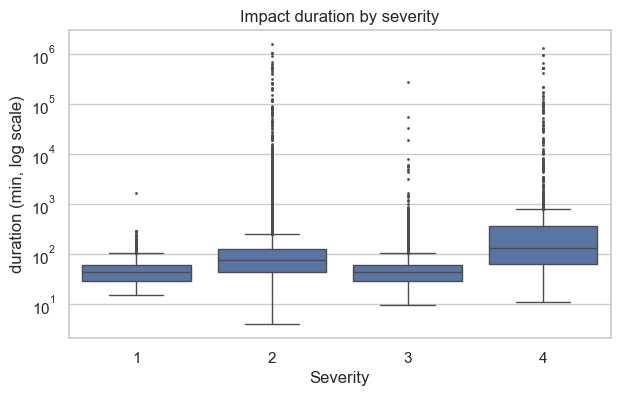

In [42]:
# Duration is EDA ONLY: End_Time is not known at report time, so it must not be a model feature.
df["duration_min"] = (df["End_Time"] - df["Start_Time"]).dt.total_seconds() / 60
print("Rows with non-positive duration:", (df["duration_min"] <= 0).sum())
valid = df[df["duration_min"] > 0]
display(valid.groupby(TARGET_COL)["duration_min"].describe().round(1))

plt.figure(figsize=(7, 4))
sns.boxplot(data=valid, x=TARGET_COL, y="duration_min", flierprops={"markersize": 1})
plt.yscale("log"); plt.ylabel("duration (min, log scale)"); plt.title("Impact duration by severity")
plt.show()

In [ ]:
# Duration extremes
print(valid["duration_min"].quantile([.01, .1, .25, .5, .9, .99, .999]).round(1))
print("Duration > 1 day:", (valid["duration_min"] > 1440).sum(), "rows")

0.010      15.0
0.100      29.5
0.250      31.4
0.500      74.8
0.900     245.5
0.990     796.7
0.999    6646.5
Name: duration_min, dtype: float64
Duration > 1 day: 2284 rows


**Notes (write in your own words):**


---
## 3. Data quality: missingness, duplicates, constant and high-cardinality columns
**Owner:** _TBD_

**Tasks**
- Missing values per column (table plus bar chart), and per row among the selected features.
- Duplicate rows and duplicate IDs.
- Constant or near-constant columns, and high-cardinality categoricals.
- Brief note per issue on how we plan to handle it (imputation, drop, etc.). Handling itself happens in the preprocessing deliverable.

,n_missing,pct_missing
End_Lng,220112,44.022752
End_Lat,220112,44.022752
Precipitation(in),142834,28.567029
Wind_Chill(F),129690,25.938208
Wind_Speed(mph),36954,7.390859
Visibility(mi),11481,2.296218
Wind_Direction,11443,2.288618
Humidity(%),11278,2.255618
Weather_Condition,11273,2.254618
Temperature(F),10610,2.122017


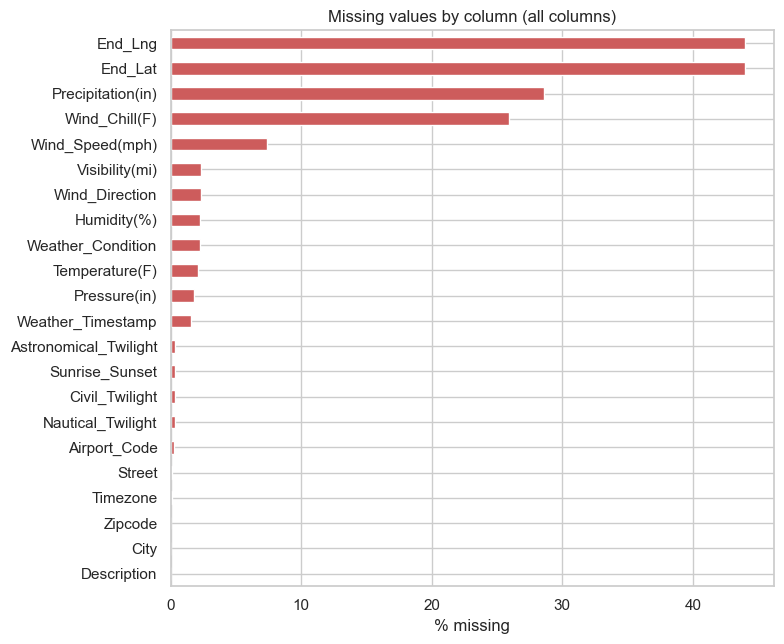

In [16]:
miss = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": df.isna().mean() * 100,
}).sort_values("pct_missing", ascending=False)
miss = miss[miss["n_missing"] > 0]
display(miss)

if len(miss):
    ax = miss["pct_missing"].plot(kind="barh", figsize=(8, max(3, 0.3 * len(miss))), color="indianred")
    ax.invert_yaxis(); ax.set_xlabel("% missing"); ax.set_title("Missing values by column (all columns)")
    plt.tight_layout(); plt.show()

Selected-feature rows with >= 1 missing value: 30.6%
Selected-feature rows with >= 3 missing values: 2.2%


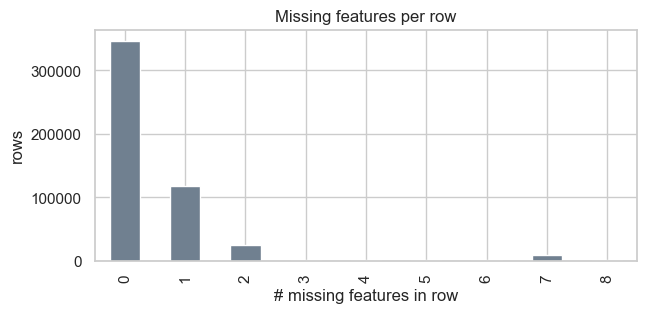

In [17]:
row_missing = df[FEATURES].isna().sum(axis=1)
print("Selected-feature rows with >= 1 missing value:", f"{(row_missing > 0).mean() * 100:.1f}%")
print("Selected-feature rows with >= 3 missing values:", f"{(row_missing >= 3).mean() * 100:.1f}%")
row_missing.value_counts().sort_index().plot(kind="bar", figsize=(7, 3), color="slategray")
plt.xlabel("# missing features in row"); plt.ylabel("rows"); plt.title("Missing features per row"); plt.show()

In [18]:
id_dups = df["ID"].duplicated().sum() if "ID" in df.columns else "n/a"
full_dups = df.drop(columns=["ID"], errors="ignore").duplicated().sum()
feat_dups = df.duplicated(subset=FEATURES + ["Start_Time"]).sum()
print("Duplicate IDs:", id_dups)
print("Fully duplicated rows (ignoring ID):", full_dups)
print("Duplicates on selected features + Start_Time:", feat_dups)

Duplicate IDs: 0
Fully duplicated rows (ignoring ID): 509
Duplicates on selected features + Start_Time: 3210


In [19]:
card = pd.DataFrame({"n_unique": df.nunique(), "dtype": df.dtypes.astype(str)})
card["pct_unique"] = card["n_unique"] / len(df) * 100
print("Constant columns:", card[card["n_unique"] <= 1].index.tolist())
print("\nHigh-cardinality object columns (> 1000 unique):")
display(card[(card["dtype"] == "object") & (card["n_unique"] > 1000)].sort_values("n_unique", ascending=False))
print("Cardinality of selected categoricals:")
display(card.loc[CATEGORICAL_FEATURES])

Constant columns: ['Country', 'Turning_Loop']

High-cardinality object columns (> 1000 unique):


,n_unique,dtype,pct_unique


Cardinality of selected categoricals:


,n_unique,dtype,pct_unique
Weather_Condition,108,str,0.0216
Sunrise_Sunset,2,str,0.0004


In [20]:
# Near-constant check on all POI-style boolean columns
poi_cols = BOOLEAN_FEATURES + LOW_VARIANCE_FEATURES
dominant = pd.DataFrame({
    "pct_dominant_value": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in poi_cols],
    "n_minority_rows": [df[c].value_counts().iloc[1:].sum() for c in poi_cols],
    "role": ["model feature"] * len(BOOLEAN_FEATURES) + ["EDA only (near-constant)"] * len(LOW_VARIANCE_FEATURES),
}, index=poi_cols).sort_values("pct_dominant_value", ascending=False).round(2)
dominant

,pct_dominant_value,n_minority_rows,role
Turning_Loop,100.00,0,EDA only (near-constant)
Roundabout,100.00,15,EDA only (near-constant)
Bump,99.96,216,EDA only (near-constant)
Traffic_Calming,99.90,491,EDA only (near-constant)
No_Exit,99.74,1278,EDA only (near-constant)
Give_Way,99.52,2388,EDA only (near-constant)
Railway,99.13,4329,model feature
Amenity,98.73,6327,model feature
Station,97.37,13151,model feature
Stop,97.22,13880,model feature


In [21]:
# Does missingness depend on severity? (e.g. is a missing Precipitation value informative?)
check_cols = ["Precipitation(in)", "Wind_Speed(mph)", "Visibility(mi)", "Weather_Condition", "End_Lat", "Wind_Chill(F)"]
miss_by_sev = pd.DataFrame({c: df[c].isna().groupby(df[TARGET_COL]).mean() * 100 for c in check_cols}).round(2)
miss_by_sev.index.name = "Severity"
print("% missing by original severity level:")
miss_by_sev

% missing by original severity level:


,Precipitation(in),Wind_Speed(mph),Visibility(mi),Weather_Condition,End_Lat,Wind_Chill(F)
Severity,,,,,,
1,5.54,1.87,1.14,1.28,57.15,3.15
2,24.22,6.50,2.26,2.21,35.92,21.75
3,49.45,11.40,2.28,2.29,87.60,46.43
4,34.29,10.64,3.88,3.84,7.04,29.53


**Notes (write in your own words):** one bullet per issue found and what we plan to do about it.

- 

---
## 4. Distributions
**Owner:** _TBD_

**Tasks**
- Histograms of the numeric features and box plots split by target class.
- Counts for the categorical features (Weather_Condition has ~100 distinct values, so it will need grouping later) and the boolean road features.
- Severity-4 rate by hour, day of week, and month.
- Mention anything skewed, outlier-heavy, or visibly different between the two classes.

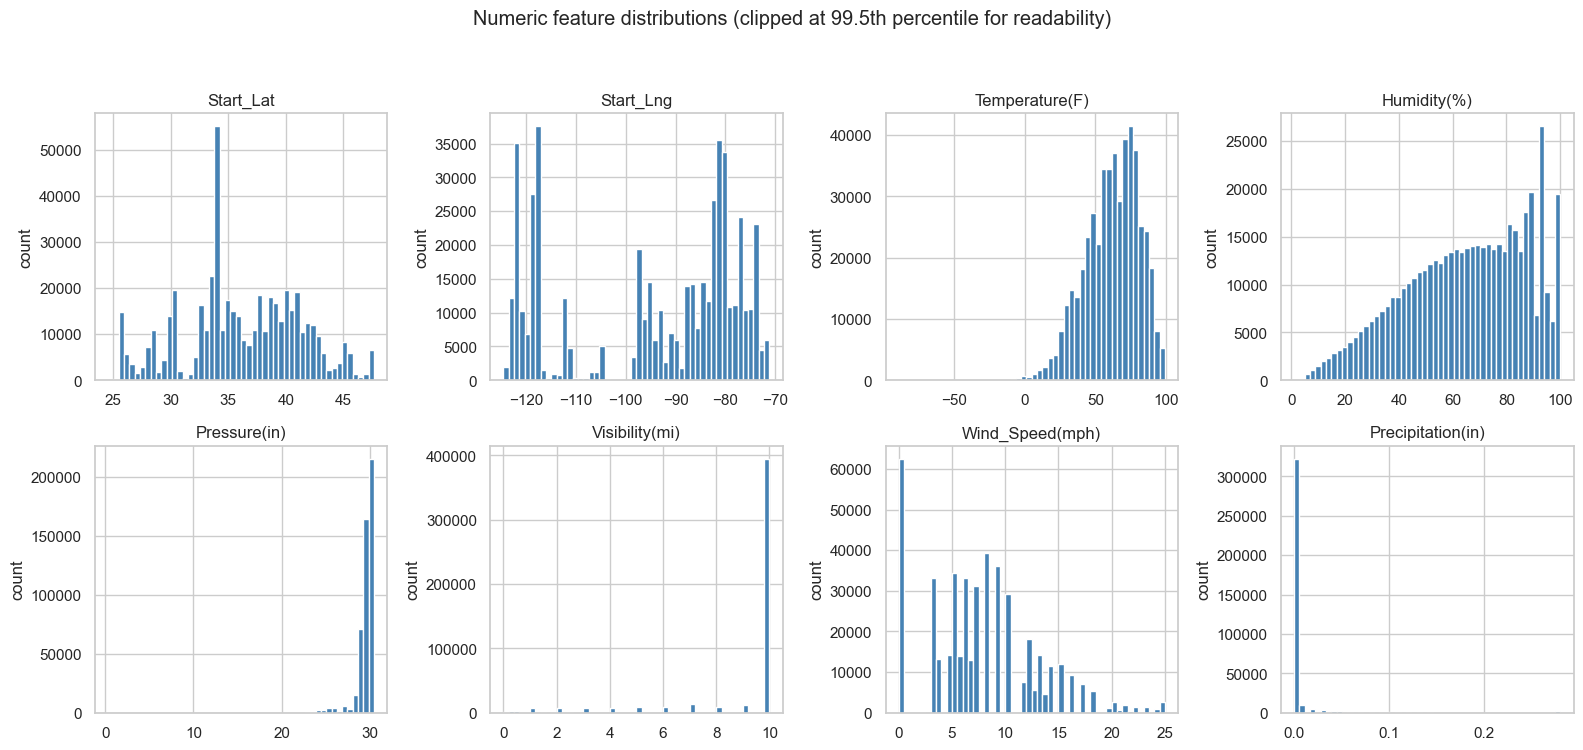

In [22]:
n_num = len(NUMERIC_FEATURES); ncols = 4; nrows = int(np.ceil(n_num / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.6 * nrows)); axes = axes.ravel()
for ax in axes[n_num:]: ax.axis("off")
for ax, col in zip(axes, NUMERIC_FEATURES):
    data = df[col].dropna()
    ax.hist(data.clip(upper=data.quantile(0.995)), bins=50, color="steelblue", edgecolor="white")
    ax.set_title(col); ax.set_ylabel("count")
fig.suptitle("Numeric feature distributions (clipped at 99.5th percentile for readability)", y=1.04)
plt.tight_layout(); plt.show()

In [23]:
# Raw values: skew, extreme maxima, implausible values
summary = df[NUMERIC_FEATURES].agg(["min", "median", "mean", "max", "skew"]).T
summary["p99.9"] = df[NUMERIC_FEATURES].quantile(0.999)
summary["pct_zero"] = (df[NUMERIC_FEATURES] == 0).mean() * 100
display(summary.round(2))
print("Wind speed > 100 mph:", (df["Wind_Speed(mph)"] > 100).sum(), "rows (implausible, flag for cleaning)")
print("Visibility > 20 mi:", (df["Visibility(mi)"] > 20).sum(), "rows (flag for review)")

,min,median,mean,max,skew,p99.9,pct_zero
Start_Lat,24.56,35.84,36.21,49.00,-0.07,48.19,0.00
Start_Lng,-124.55,-87.77,-94.71,-67.55,-0.48,-70.92,0.00
Temperature(F),-89.00,64.00,61.65,172.00,-0.51,105.80,0.04
Humidity(%),1.00,67.00,64.86,100.00,-0.40,100.00,0.00
Pressure(in),0.30,29.86,29.54,39.45,-3.73,30.68,0.00
Visibility(mi),0.00,10.00,9.09,100.00,2.45,30.00,0.11
Wind_Speed(mph),0.00,7.00,7.68,243.00,1.17,31.00,12.50
Precipitation(in),0.00,0.00,0.01,10.16,82.65,0.66,64.50


Wind speed > 100 mph: 8 rows (implausible, flag for cleaning)
Visibility > 20 mi: 677 rows (flag for review)


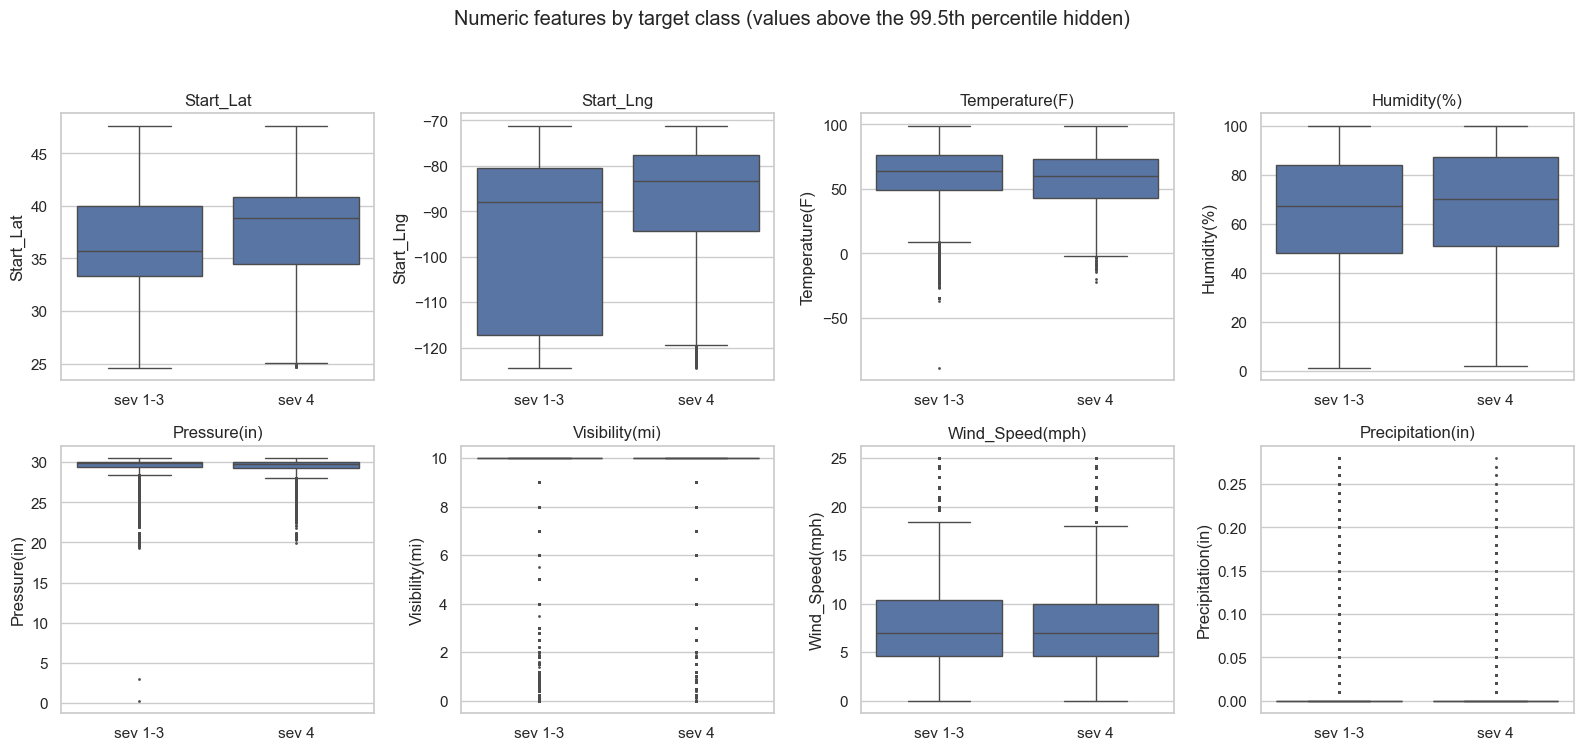

In [24]:
n_num = len(NUMERIC_FEATURES); ncols = 4; nrows = int(np.ceil(n_num / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.6 * nrows)); axes = axes.ravel()
for ax in axes[n_num:]: ax.axis("off")
for ax, col in zip(axes, NUMERIC_FEATURES):
    data = df[[col, "target"]].dropna()
    q = data[col].quantile(0.995)
    sns.boxplot(data=data[data[col] <= q], x="target", y=col, ax=ax, flierprops={"markersize": 1})
    ax.set_xticklabels(["sev 1-3", "sev 4"]); ax.set_xlabel(""); ax.set_title(col)
fig.suptitle("Numeric features by target class (values above the 99.5th percentile hidden)", y=1.04)
plt.tight_layout(); plt.show()

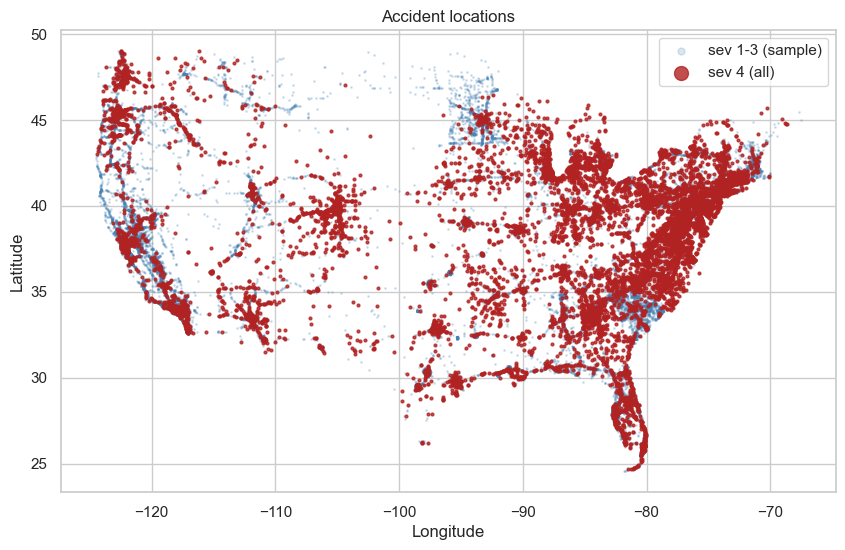

In [25]:
# Location: all severity-4 accidents plus a random sample of the rest
neg = df[df["target"] == 0].sample(min((df["target"] == 0).sum(), 100000), random_state=RANDOM_SEED)
pos = df[df["target"] == 1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(neg["Start_Lng"], neg["Start_Lat"], s=1, alpha=0.2, color="steelblue", label="sev 1-3 (sample)")
ax.scatter(pos["Start_Lng"], pos["Start_Lat"], s=4, alpha=0.8, color="firebrick", label="sev 4 (all)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_title("Accident locations")
ax.legend(markerscale=5); plt.show()

Distinct Weather_Condition values: 108


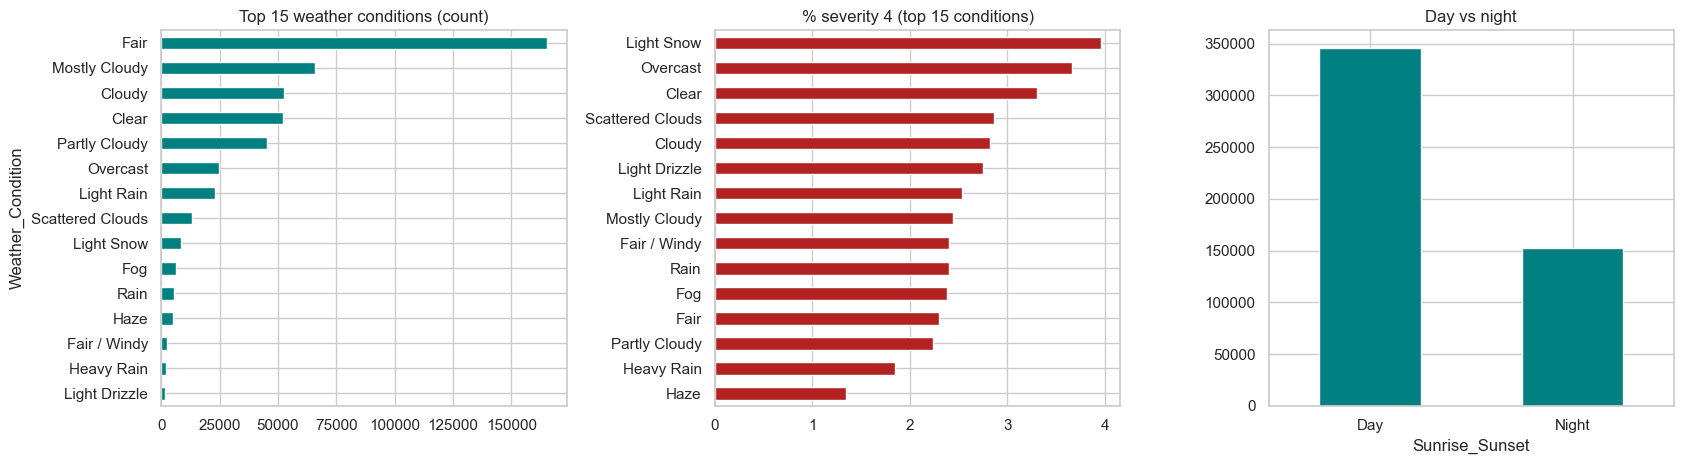

In [26]:
print("Distinct Weather_Condition values:", df["Weather_Condition"].nunique())
top = df["Weather_Condition"].value_counts().head(15).index
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
df["Weather_Condition"].value_counts().head(15).plot(kind="barh", ax=axes[0], color="teal")
axes[0].invert_yaxis(); axes[0].set_title("Top 15 weather conditions (count)")
(df[df["Weather_Condition"].isin(top)].groupby("Weather_Condition")["target"].mean() * 100).sort_values().plot(
    kind="barh", ax=axes[1], color="firebrick")
axes[1].set_title("% severity 4 (top 15 conditions)"); axes[1].set_ylabel("")
df["Sunrise_Sunset"].value_counts().plot(kind="bar", ax=axes[2], color="teal")
axes[2].set_title("Day vs night"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [27]:
bool_rates = pd.DataFrame({
    "pct_True": [df[c].mean() * 100 for c in BOOLEAN_FEATURES],
    "sev4_rate_if_True (%)": [df.loc[df[c] == True, "target"].mean() * 100 for c in BOOLEAN_FEATURES],
    "sev4_rate_if_False (%)": [df.loc[df[c] == False, "target"].mean() * 100 for c in BOOLEAN_FEATURES],
}, index=BOOLEAN_FEATURES).round(2)
bool_rates

,pct_True,sev4_rate_if_True (%),sev4_rate_if_False (%)
Amenity,1.27,1.96,2.66
Crossing,11.39,1.55,2.80
Junction,7.37,3.51,2.59
Railway,0.87,2.26,2.66
Station,2.63,1.58,2.68
Stop,2.78,2.66,2.65
Traffic_Signal,14.76,1.79,2.80


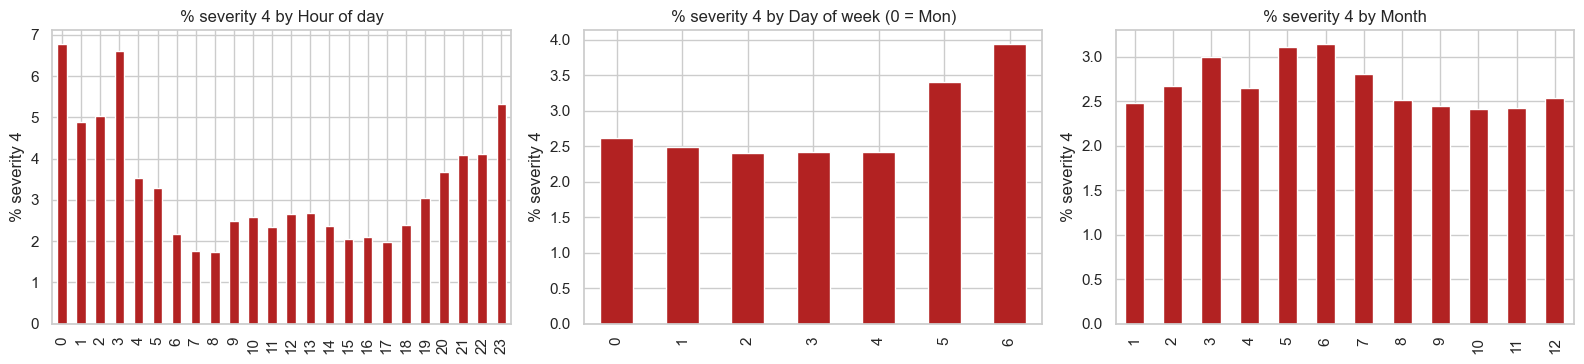

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col, title in zip(axes, ["hour", "dayofweek", "month"], ["Hour of day", "Day of week (0 = Mon)", "Month"]):
    (df.groupby(col)["target"].mean() * 100).plot(kind="bar", ax=ax, color="firebrick")
    ax.set_title(f"% severity 4 by {title}"); ax.set_ylabel("% severity 4"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Notes (write in your own words):**

- 

---
## 5. Correlation analysis
**Owner:** _TBD_

**Tasks**
- Correlation heatmap for numeric, boolean (as 0/1), time-derived features and the target.
- Highlight highly correlated feature pairs (e.g. |r| > 0.7), which matters later for feature selection.
- Correlation of each feature with the target.

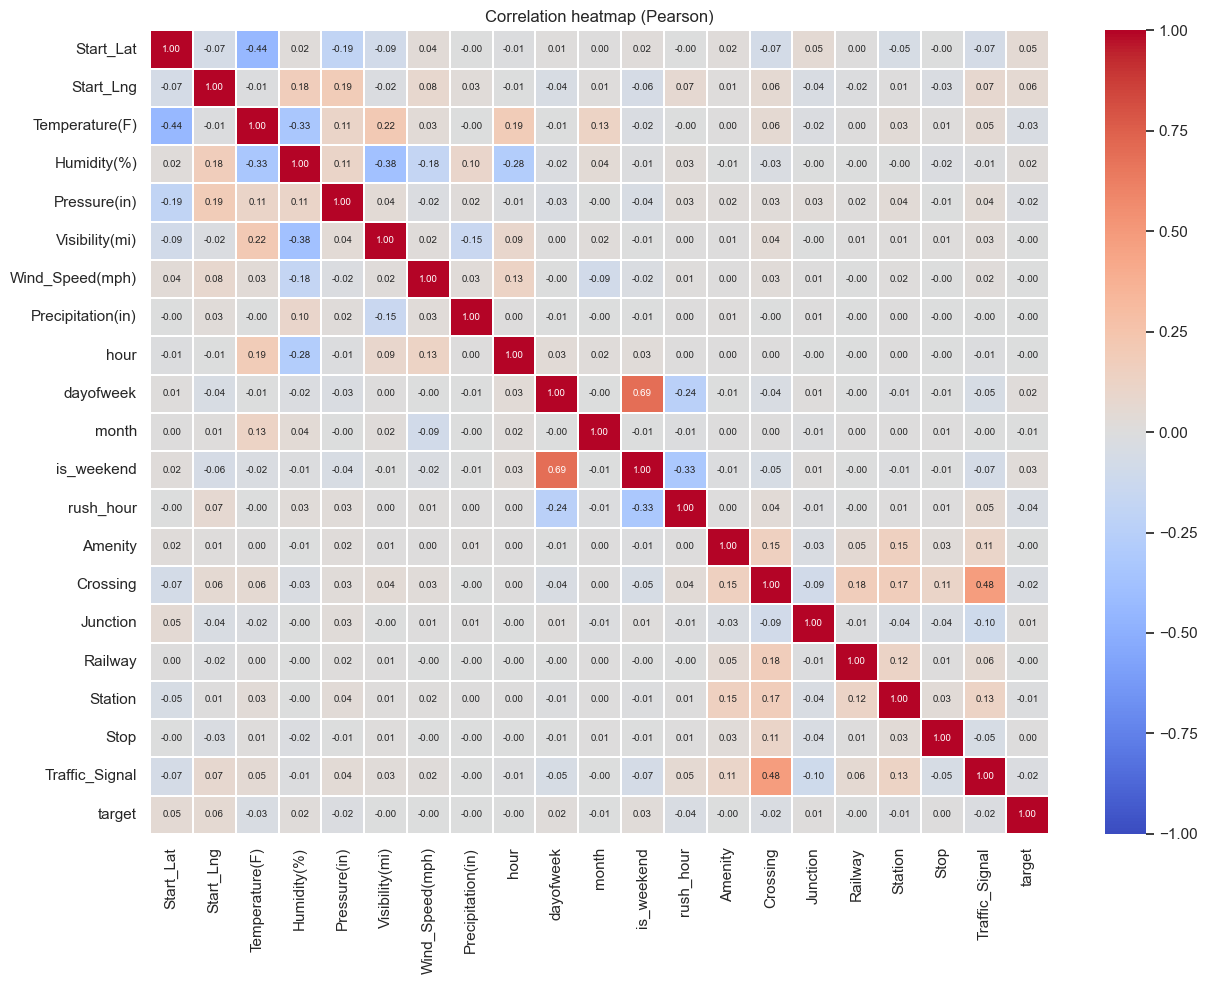

In [29]:
corr_df = df[NUMERIC_FEATURES + DERIVED_TIME_FEATURES].copy()
for c in BOOLEAN_FEATURES:
    corr_df[c] = df[c].astype(float)
corr_df["target"] = df["target"]

corr = corr_df.corr(numeric_only=True)
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=0.3)
plt.title("Correlation heatmap (Pearson)")
plt.tight_layout(); plt.show()

Highly correlated feature pairs (|r| > 0.7):


,,r


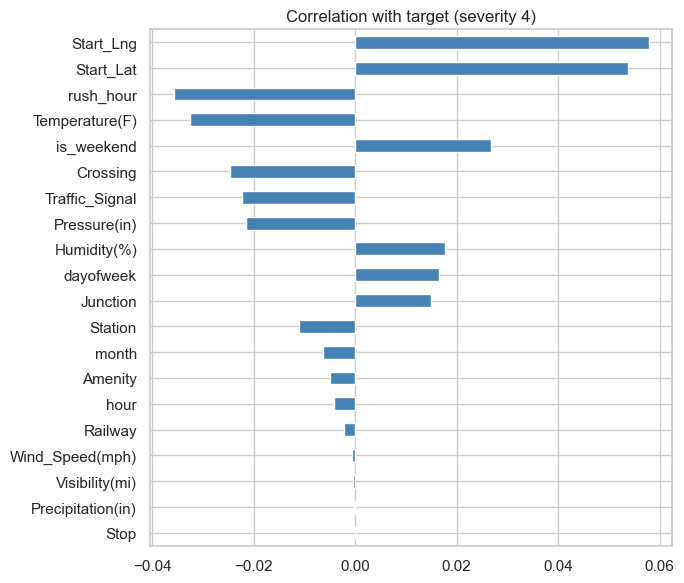

In [30]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False)
print("Highly correlated feature pairs (|r| > 0.7):")
display(strong.to_frame("r"))

target_corr = corr["target"].drop("target").sort_values(key=abs, ascending=False)
ax = target_corr.plot(kind="barh", figsize=(7, 6), color="steelblue")
ax.invert_yaxis(); ax.set_title("Correlation with target (severity 4)"); plt.tight_layout(); plt.show()

**Notes (write in your own words):**

- 

---
## 6. Key insights and challenges
**Owner:** whole team (write together after sections 1-5 are merged)

Summarise in your own words:
1. Class imbalance and how it changes across years
2. Missing data (which columns, how much, how we plan to handle it)
3. Leakage risks and which columns are excluded
4. Highly correlated or redundant features
5. Skewed features and outliers
6. What this means for preprocessing and modelling next

-

import os; os.makedirs("data", exist_ok=True)
   df_raw.to_csv("data/US_Accidents_March23_sampled_500k.csv", index=False)